In [5]:

import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"

import zipfile
import io
import requests

response = requests.get(url, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("student-mat.csv") as f:
            df = pd.read_csv(f, sep=";")

            print("Dataset downloaded successfully!")
            print("Total student records:", len(df))
            print(df.head())


Dataset downloaded successfully!
Total student records: 395
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [6]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFinal grade statistics:")
print(df["G3"].describe())

Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values:
0

Final grade statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


In [7]:

features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X = df[features].copy()

# Original final grade is out of 20.
# Convert it to a 100-mark scale.
y = df["G3"] * 5

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nSample inputs:")
print(X.head())

print("\nSample target marks out of 100:")
print(y.head())

Input data shape: (395, 6)
Target data shape: (395,)

Sample inputs:
   age  studytime  failures  absences  G1  G2
0   18          2         0         6   5   6
1   17          2         0         4   5   5
2   15          2         3        10   7   8
3   15          3         0         2  15  14
4   16          2         0         4   6  10

Sample target marks out of 100:
0    30
1    30
2    50
3    75
4    50
Name: G3, dtype: int64


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 316
Testing records: 79


In [10]:

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)

model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")

Machine Learning model trained successfully!


In [11]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE: {mae:.2f} marks")
print(f"RMSE: {rmse:.2f} marks")
print(f"R2 Score: {r2:.3f}")

MAE: 5.27 marks
RMSE: 8.82 marks
R2 Score: 0.848


In [12]:

def get_grade(marks):
    if marks < 35:
        return "FAIL", "FAIL"
    elif marks < 40:
        return "P", "PASS"
    elif marks < 50:
        return "C", "PASS"
    elif marks < 60:
        return "B", "PASS"
    elif marks < 70:
        return "B+", "PASS"
    elif marks < 80:
        return "A", "PASS"
    elif marks < 90:
        return "A+", "PASS"
    else:
        return "O", "PASS"


print("Grading system test:")
for marks in [20, 35, 38, 45, 55, 65, 75, 85, 95, 100]:
    grade, result = get_grade(marks)
    print(f"Marks: {marks:3} | Grade: {grade:4} | Result: {result}")

Grading system test:
Marks:  20 | Grade: FAIL | Result: FAIL
Marks:  35 | Grade: P    | Result: PASS
Marks:  38 | Grade: P    | Result: PASS
Marks:  45 | Grade: C    | Result: PASS
Marks:  55 | Grade: B    | Result: PASS
Marks:  65 | Grade: B+   | Result: PASS
Marks:  75 | Grade: A    | Result: PASS
Marks:  85 | Grade: A+   | Result: PASS
Marks:  95 | Grade: O    | Result: PASS
Marks: 100 | Grade: O    | Result: PASS


In [13]:

def predict_student_performance(
    age, studytime, failures, absences, G1, G2
):
    student = pd.DataFrame(
        [[age, studytime, failures, absences, G1, G2]],
        columns=features
    )

    predicted_marks = float(model.predict(student)[0])

    # Keep the prediction within the 0–100 scale
    predicted_marks = max(0, min(100, predicted_marks))
    predicted_marks = round(predicted_marks, 2)

    grade, result = get_grade(predicted_marks)

    print("\n===== STUDENT PERFORMANCE REPORT =====")
    print("Age:", age)
    print("Weekly study-time category:", studytime)
    print("Previous failures:", failures)
    print("Absences:", absences)
    print("First-period grade:", G1, "/ 20")
    print("Second-period grade:", G2, "/ 20")
    print("--------------------------------------")
    print("Predicted Marks:", predicted_marks, "/ 100")
    print("Grade:", grade)
    print("Result:", result)
    print("======================================")

    return predicted_marks, grade, result

In [14]:

predict_student_performance(
    age=17,
    studytime=3,
    failures=0,
    absences=3,
    G1=14,
    G2=15
)


===== STUDENT PERFORMANCE REPORT =====
Age: 17
Weekly study-time category: 3
Previous failures: 0
Absences: 3
First-period grade: 14 / 20
Second-period grade: 15 / 20
--------------------------------------
Predicted Marks: 78.51 / 100
Grade: A
Result: PASS


(78.51, 'A', 'PASS')

In [15]:

predict_student_performance(
    age=16,
    studytime=1,
    failures=2,
    absences=15,
    G1=5,
    G2=6
)


===== STUDENT PERFORMANCE REPORT =====
Age: 16
Weekly study-time category: 1
Previous failures: 2
Absences: 15
First-period grade: 5 / 20
Second-period grade: 6 / 20
--------------------------------------
Predicted Marks: 28.75 / 100
Grade: FAIL
Result: FAIL


(28.75, 'FAIL', 'FAIL')

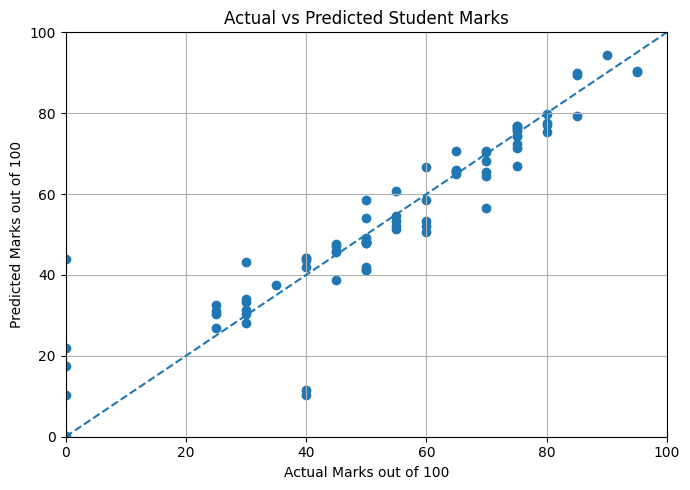

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)
plt.plot([0, 100], [0, 100], linestyle="--")

plt.xlabel("Actual Marks out of 100")
plt.ylabel("Predicted Marks out of 100")
plt.title("Actual vs Predicted Student Marks")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:

test_marks = [0, 34, 35, 39, 40, 49, 50, 59,
              60, 69, 70, 79, 80, 89, 90, 100]

test_results = []

for marks in test_marks:
    grade, result = get_grade(marks)
    test_results.append({
        "Input Marks": marks,
        "Expected Grade": grade,
        "Expected Result": result
    })

test_df = pd.DataFrame(test_results)
display(test_df)

,Input Marks,Expected Grade,Expected Result
0,0,FAIL,FAIL
1,34,FAIL,FAIL
2,35,P,PASS
3,39,P,PASS
4,40,C,PASS
5,49,C,PASS
6,50,B,PASS
7,59,B,PASS
8,60,B+,PASS
9,69,B+,PASS


In [18]:

evaluation_df = pd.DataFrame({
    "Actual_Marks": y_test.to_numpy(),
    "Predicted_Marks": predictions.round(2)
})

evaluation_df.to_csv(
    "prediction_results.csv",
    index=False
)

test_df.to_csv("grading_test_cases.csv", index=False)

print("Evaluation and grading test files saved.")

Evaluation and grading test files saved.


In [19]:

import joblib

joblib.dump(model, "student_performance_model.pkl")

print("Trained model saved successfully.")

Trained model saved successfully.


In [20]:

evaluation_df = pd.DataFrame({
    "Actual_Marks": y_test.to_numpy(),
    "Predicted_Marks": np.round(predictions, 2)
})

evaluation_df.to_csv("prediction_results.csv", index=False)
test_df.to_csv("grading_test_cases.csv", index=False)
joblib.dump(model, "student_performance_model.pkl")

print("All 3 files created successfully!")

All 3 files created successfully!
